# Modeling Human Activity States (Body state) with Hidden Markov Models

**Assignment: Formative 2, Hidden Markov Models**

In this activity we recognize four human activities (standing, walking, jumping, still) from smartphone accelerometer and gyroscope signals, using a Hidden Markov Model implemented from scratch with NumPy.

| Step | What happens |
|---|---|
| 1. Data collection and loading | Raw Sensor Logger recordings (iPhone 13, 50 Hz) are loaded and inspected |
| 2. Data cleaning | Both sensors are resampled to an exact 50 Hz grid, clipped to 8 s and labelled |
| 3. Feature extraction | 2 s windows, 10 time- and frequency-domain features, Z-score normalization |
| 4. HMM implementation | Gaussian-emission HMM, Baum-Welch training, Viterbi decoding |
| 5. Hyperparameter tuning | Recording-level cross-validation on the training set |
| 6. Evaluation | Unseen test recordings: metrics table, confusion matrix, probability plots, decoded sequence |
| 7. Analysis and reflection | Findings and possible improvements |

**Layout:** `raw_data/` (original exports), `clean_data/` (cleaned CSV files), `features/` (feature tables), `figures/` (saved plots), and this notebook.

**Prepared by: Alain Ishimwe Ngabo**

**Facilitator: Marvin Ogore**

## Project Setup & Dependencies

In [1]:
from collections import Counter
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
RAW_DIR = Path("raw_data")
TRAIN_DIR = RAW_DIR / "train_set"
TEST_DIR = RAW_DIR / "test_set"
CLEAN_DIR = Path("clean_data")
FIG_DIR = Path("figures")
FEATURE_DIR = Path("features")
FIG_DIR.mkdir(exist_ok=True)
FEATURE_DIR.mkdir(exist_ok=True)

FS = 50    # target sampling rate (Hz)
CLIP_SEC = 8    # 8 seconds to be kept from the middle of each recording
WINDOW_SEC = 2  # window length (s)
OVERLAP = 0.5   # overlap between consecutive windows
EPS = 1e-8      # avoiding log(0)
ACTIVITIES = ["standing", "walking", "jumping", "still"]
STATE_INDEX = {name: i for i, name in enumerate(ACTIVITIES)}

## 1. Data Collection and Loading

All data was recorded with **Sensor Logger** on an **iPhone 13**, using only the **accelerometer** and **gyroscope** (x, y, z). Four activities were recorded: standing, walking, jumping and still.

- **Training set:** 14 recordings per activity (56 in total).
- **Test set:** 4 recordings per activity (16 in total), recorded in a separate session on 25 October 2026. They are never used for training, tuning or normalization.
- Each raw recording is a folder with the sensor files and `Metadata.csv`. Only the calibrated `Accelerometer.csv` and `Gyroscope.csv` files are used.

### 1.1. Loading the recordings

In [3]:
def list_recordings(folder):
    """Return all recording folders inside a split folder."""
    return sorted(p for p in folder.iterdir() if p.is_dir())


train_recs = list_recordings(TRAIN_DIR)
test_recs = list_recordings(TEST_DIR)

print("Train recordings:", len(train_recs))
print("Test recordings:", len(test_recs))
print(Counter(p.name.split("_")[0] for p in train_recs))
print([p.name for p in test_recs])

Train recordings: 56
Test recordings: 16
Counter({'jumping': 14, 'standing': 14, 'still': 14, 'walking': 14})
['jumping_15-2026-10-25_21-48-11', 'jumping_16-2026-10-25_21-48-25', 'jumping_17-2026-10-25_21-48-42', 'jumping_18-2026-10-25_21-49-00', 'standing_15-2026-10-25_21-45-33', 'standing_16-2026-10-25_21-45-47', 'standing_17-2026-10-25_21-46-01', 'standing_18-2026-10-25_21-46-15', 'still_15-2026-10-25_21-38-28', 'still_16-2026-10-25_21-38-14', 'still_17-2026-10-25_21-37-54', 'still_18-2026-10-25_21-37-39', 'walking_15-2026-10-25_21-41-43', 'walking_16-2026-10-25_21-40-53', 'walking_17-2026-10-25_21-41-17', 'walking_18-2026-10-25_21-40-29']


**Outcome:** 56 training and 16 test recordings were found, balanced across the four activities (14 and 4 per activity).

### 1.2. Inspecting one recording

In [4]:
rec = train_recs[0]

for sensor in ["Accelerometer", "Gyroscope"]:
    df = pd.read_csv(rec / f"{sensor}.csv")
    rate = 1 / df["seconds_elapsed"].diff().median()
    print(f"\n{sensor}: {df.shape[0]} rows, about {rate:.1f} Hz")
    print(df.head(5))


Accelerometer: 635 rows, about 49.8 Hz
                  time  seconds_elapsed         z         y         x
0  1792797592703957800         0.061958  0.311015 -0.149404  0.062188
1  1792797592724023800         0.082024  0.186087 -0.108752 -0.287363
2  1792797592744089600         0.102090  0.215011 -0.086099 -0.136901
3  1792797592764155600         0.122156  0.245623 -0.057171 -0.039290
4  1792797592784221700         0.142222  0.139733 -0.163706 -0.089937

Gyroscope: 635 rows, about 49.8 Hz
                  time  seconds_elapsed         z         y         x
0  1792797592703957800         0.061958  0.061624 -0.020259  0.154794
1  1792797592724023800         0.082024  0.024721 -0.019868  0.238840
2  1792797592744089600         0.102090  0.024550 -0.029561  0.269234
3  1792797592764155600         0.122156  0.028554 -0.042452  0.237523
4  1792797592784221700         0.142222  0.046855 -0.056290  0.230333


**Outcome:** Both sensors share the same timestamps and measure about 49.8 Hz, slightly below the nominal 50 Hz. The timestamps are therefore not perfectly regular, which is why the recordings are resampled in Section 2.

### 1.3. Phone specification

In [5]:
meta = pd.read_csv(rec / "Metadata.csv").iloc[0]
print(meta[["device name", "platform", "platform version", "appVersion", "sampleRateMs"]].to_string())

device name            iPhone 13
platform                     ios
platform version            26.5
appVersion                  1.68
sampleRateMs        20|20||20|20


**Outcome:** Recordings come from one **iPhone 13** running Sensor Logger 1.68. `sampleRateMs = 20` means one sample every 20 ms, a nominal **50 Hz** for both sensors. With a single phone there is one sampling rate and one set of units. The cleaning step still resamples every recording to an exact 50 Hz grid, so the pipeline would also work with recordings from other phones.

## 2. Data Cleaning

Each recording is cleaned in four steps:

1. **Align** the accelerometer and gyroscope on a common time range.
2. **Resample** both sensors to an exact 50 Hz grid with linear interpolation. The real rate was about 49.8 Hz, so this removes small timing jitter and gives every file the same sampling rate.
3. **Clip** the middle 8 seconds. The first and last seconds contain the start and stop button presses, and clipping gives every sample the same length.
4. **Label** each file with its activity and save one CSV per recording in `clean_data/`.

### 2.1. Clean and save

In [6]:
def load_sensor(rec_dir, sensor, prefix):
    """Load one sensor file and prefix its axis columns."""
    df = pd.read_csv(rec_dir / f"{sensor}.csv")
    df = df.rename(columns={axis: f"{prefix}_{axis}" for axis in "xyz"})
    return df[["seconds_elapsed", f"{prefix}_x", f"{prefix}_y", f"{prefix}_z"]]


def clean_recording(rec_dir):
    """Put both sensors on one exact 50 Hz grid and keep the middle CLIP_SEC seconds."""
    sensors = [load_sensor(rec_dir, "Accelerometer", "acc"),
               load_sensor(rec_dir, "Gyroscope", "gyro")]
    start = max(df["seconds_elapsed"].iloc[0] for df in sensors)
    end = min(df["seconds_elapsed"].iloc[-1] for df in sensors)

    if end - start >= CLIP_SEC:
        mid = (start + end) / 2
        start, end = mid - CLIP_SEC / 2, mid + CLIP_SEC / 2
    else:
        print(f"Short recording ({end - start:.1f}s): {rec_dir.name}")
    grid = np.arange(start, end, 1 / FS)

    clean = pd.DataFrame({"timestamp": grid - start})
    for df in sensors:
        for col in df.columns[1:]:
            clean[col] = np.interp(grid, df["seconds_elapsed"], df[col])
    return clean


def clean_split(recs, out_dir):
    """Clean every recording in a split and save one CSV per sample."""
    out_dir.mkdir(parents=True, exist_ok=True)
    for rec_dir in recs:
        name = rec_dir.name.split("-")[0]  # ex: 'jumping_15'
        clean = clean_recording(rec_dir)
        clean["activity"] = name.split("_")[0]
        clean.to_csv(out_dir / f"{name}.csv", index=False)


clean_split(train_recs, CLEAN_DIR / "train")
clean_split(test_recs, CLEAN_DIR / "test")
print("Cleaned data saved to", CLEAN_DIR)

Cleaned data saved to clean_data


### 2.2. Check Dataset 

In [7]:
def summarize(folder):
    """Count files and seconds of data per activity."""
    rows = []
    for f in sorted(folder.glob("*.csv")):
        df = pd.read_csv(f)
        rows.append({"activity": df["activity"].iloc[0],
                     "seconds": df["timestamp"].iloc[-1]})
    return (pd.DataFrame(rows).groupby("activity")["seconds"]
            .agg(files="count", total_seconds="sum", mean_seconds="mean").round(1))


print("Train"); print(summarize(CLEAN_DIR / "train"))
print()
print("Test");  print(summarize(CLEAN_DIR / "test"))

Train
          files  total_seconds  mean_seconds
activity                                    
jumping      14          111.7           8.0
standing     14          111.7           8.0
still        14          111.7           8.0
walking      14          111.7           8.0

Test
          files  total_seconds  mean_seconds
activity                                    
jumping       4           31.9           8.0
standing      4           31.9           8.0
still         4           31.9           8.0
walking       4           31.9           8.0


**Outcome:** Every activity has 14 training files of 8 s (about 112 s in total, above the 90 s minimum) and 4 test files of 8 s. All files have the same length and the same 50 Hz sampling rate.

### 2.3. Sample signals

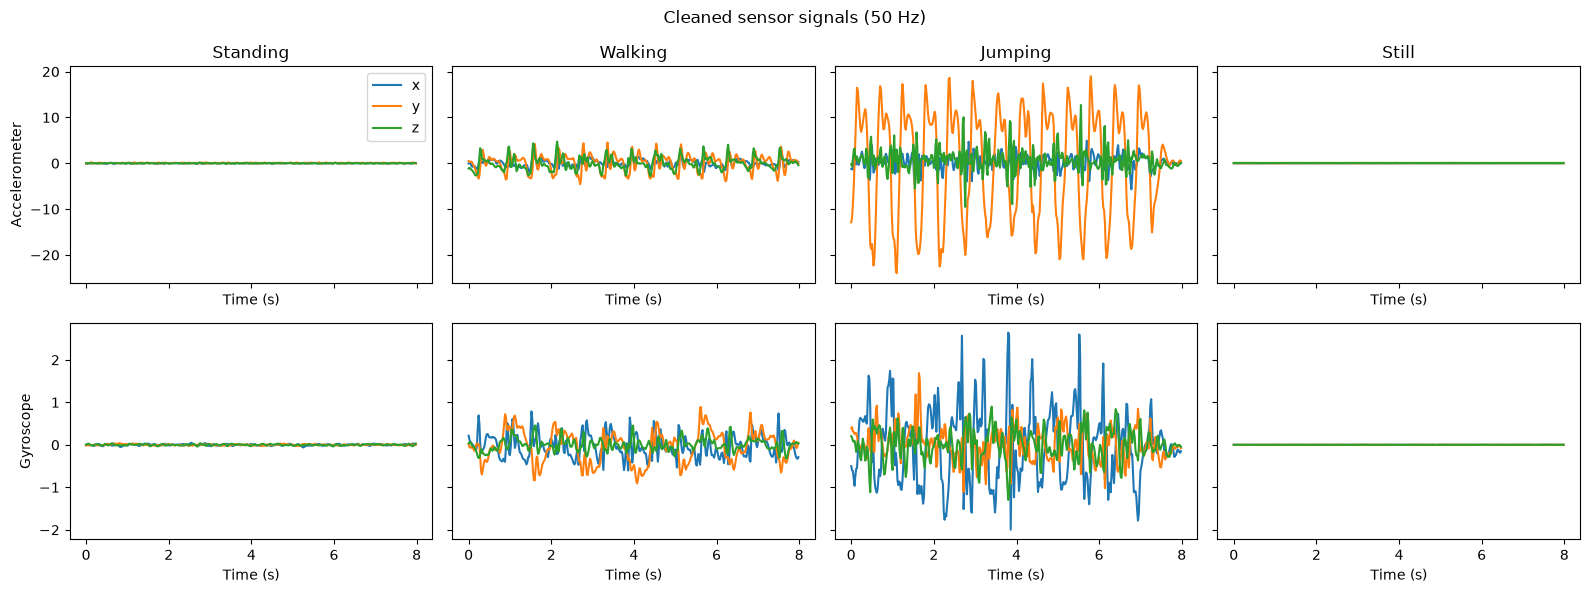

In [8]:
def plot_samples(activities=("standing", "walking", "jumping", "still")):
    """Plot one cleaned recording per activity for both sensors."""
    fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharex=True, sharey="row")
    sensors = [("acc", "Accelerometer"), ("gyro", "Gyroscope")]
    for col, activity in enumerate(activities):
        df = pd.read_csv(CLEAN_DIR / "train" / f"{activity}_01.csv")
        for row, (prefix, title) in enumerate(sensors):
            for axis in "xyz":
                axes[row, col].plot(df["timestamp"], df[f"{prefix}_{axis}"], label=axis)
            if row == 0:
                axes[row, col].set_title(activity.capitalize())
            if col == 0:
                axes[row, col].set_ylabel(title)
            axes[row, col].set_xlabel("Time (s)")
    axes[0, 0].legend(loc="upper right")
    fig.suptitle("Cleaned sensor signals (50 Hz)")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "sample_signals.png", dpi=150)
    plt.show()


plot_samples()

**Outcome:** The four activities are clearly different. *Still* is flat, *standing* shows only small noise, *walking* shows a moderate regular pattern, and *jumping* shows large repeated peaks, mainly on the y-axis of the accelerometer. The accelerometer is centred on zero, so gravity is already removed and the signal size measures how strongly the phone moves.

## 3. Feature Extraction

### 3.1. Windowing
Each 8 s recording is cut into **2 s windows (100 samples at 50 Hz) with 50% overlap**, which gives 7 windows per recording.

Why 2 s:
- It covers several walking steps and jump cycles (typically 1 to 3 Hz), so the frequency features are reliable.
- 100 samples give a frequency resolution of 0.5 Hz. The Nyquist limit of 25 Hz is far above human movement frequencies.
- It is short enough to react to a change of activity.
- 50% overlap doubles the number of windows without losing information.

Section 5.2 compares 1 s, 2 s and 3 s windows.

In [9]:
win = int(WINDOW_SEC * FS)
step = int(win * (1 - OVERLAP))
print(f"Window length: {WINDOW_SEC} s = {win} samples at {FS} Hz")
print(f"Step: {step} samples ({OVERLAP:.0%} overlap)")
print(f"Frequency resolution: {FS / win:.2f} Hz, Nyquist limit: {FS / 2:.0f} Hz")

Window length: 2 s = 100 samples at 50 Hz
Step: 50 samples (50% overlap)
Frequency resolution: 0.50 Hz, Nyquist limit: 25 Hz


### 3.2. Feature extraction
Five features are computed for each sensor (accelerometer and gyroscope), so each window has **10 features**. The time-domain features use the signal magnitude or the three axes; the frequency-domain features come from the FFT of the signal magnitude.

| Feature | Domain | Definition | Why it helps |
|---|---|---|---|
| `log_std` | Time | Log of the standard deviation of the signal magnitude | Measures movement strength: still < standing < walking < jumping. The log scale keeps small differences visible |
| `log_sma` | Time | Log of the signal magnitude area (mean of \|x\|+\|y\|+\|z\|) | Overall activity level across all three axes |
| `corr` | Time | Mean absolute correlation between the x, y and z axes | Shows how the axes move together; movements with one dominant direction have correlated axes |
| `dom_freq` | Frequency (FFT) | Frequency of the largest FFT peak (0 Hz removed) | Captures the rhythm of steps and jumps |
| `entropy` | Frequency (FFT) | Normalized spectral entropy | Low for periodic movement (walking, jumping), high for noise-like signals (still, standing) |

In [10]:
SENSORS = {"acc": ["acc_x", "acc_y", "acc_z"],
           "gyro": ["gyro_x", "gyro_y", "gyro_z"]}


def spectral_features(signal):
    """Return dominant frequency (Hz) and normalized spectral entropy."""
    signal = signal - signal.mean()
    power = np.abs(np.fft.rfft(signal)) ** 2
    freqs = np.fft.rfftfreq(len(signal), d=1 / FS)
    power, freqs = power[1:], freqs[1:]  # drop the 0 Hz term
    dom_freq = freqs[np.argmax(power)]
    p = power / (power.sum() + EPS)
    entropy = -np.sum(p * np.log2(p + EPS)) / np.log2(len(p))
    return dom_freq, entropy


def mean_abs_corr(xyz):
    """Mean absolute correlation between the x, y and z axes."""
    with np.errstate(invalid="ignore", divide="ignore"):
        corr = np.corrcoef(xyz.T)
    pairs = np.abs(corr[np.triu_indices(3, k=1)])
    return np.nan_to_num(pairs).mean()


def window_features(window):
    """Compute the 10 features of one window."""
    feats = {}
    for prefix, cols in SENSORS.items():
        xyz = window[cols].to_numpy()
        magnitude = np.linalg.norm(xyz, axis=1)
        dom_freq, entropy = spectral_features(magnitude)
        feats[f"{prefix}_log_std"] = np.log(magnitude.std() + EPS)
        feats[f"{prefix}_log_sma"] = np.log(np.abs(xyz).sum(axis=1).mean() + EPS)
        feats[f"{prefix}_corr"] = mean_abs_corr(xyz)
        feats[f"{prefix}_dom_freq"] = dom_freq
        feats[f"{prefix}_entropy"] = entropy
    return feats


def build_feature_table(folder, window_sec=WINDOW_SEC):
    """Slide a window over every clean recording and collect the features."""
    win = int(window_sec * FS)
    step = int(win * (1 - OVERLAP))
    rows = []
    for path in sorted(folder.glob("*.csv")):
        df = pd.read_csv(path)
        for i, start in enumerate(range(0, len(df) - win + 1, step)):
            feats = window_features(df.iloc[start:start + win])
            rows.append({"recording": path.stem,
                         "activity": df["activity"].iloc[0],
                         "window": i, **feats})
    return pd.DataFrame(rows)


train_feats = build_feature_table(CLEAN_DIR / "train")
test_feats = build_feature_table(CLEAN_DIR / "test")

print(train_feats.groupby("activity").size())
print(test_feats.groupby("activity").size())

activity
jumping     98
standing    98
still       98
walking     98
dtype: int64
activity
jumping     28
standing    28
still       28
walking     28
dtype: int64


**Outcome:** Each activity gives 98 training windows (14 recordings x 7 windows) and 28 test windows (4 recordings x 7 windows).

### 3.3. Z-score normalization
The features have very different ranges (Hz, log values, correlations). **Z-score normalization** puts them on one scale, so no feature dominates the Gaussian emissions of the HMM. The mean and standard deviation are computed on the **training set only** and then applied to the test set, so no test information leaks into training.

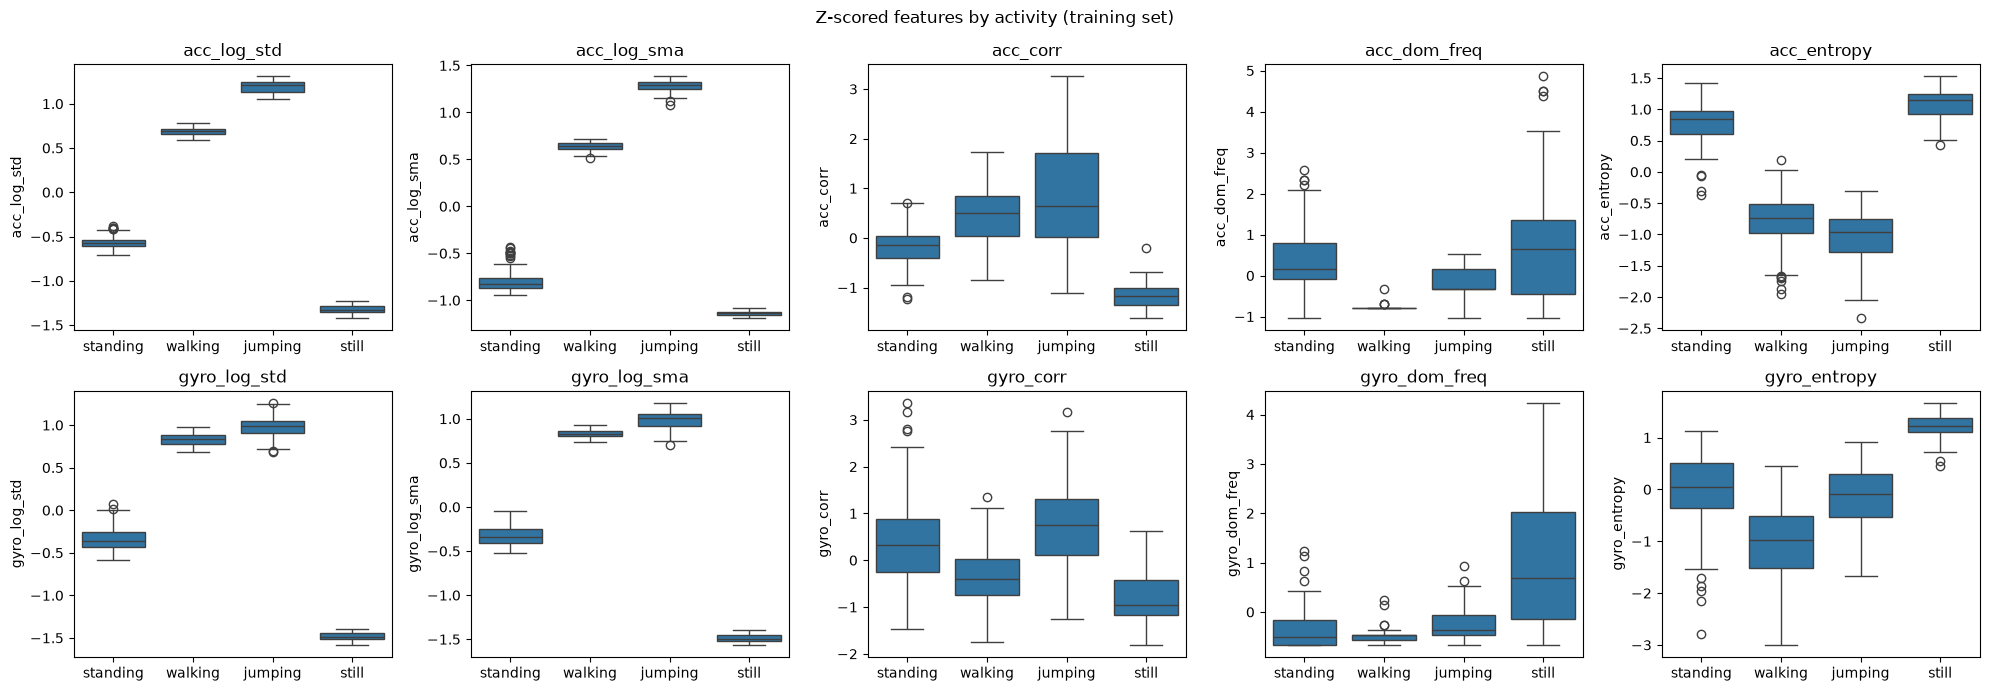

In [11]:
FEATURE_COLS = [c for c in train_feats.columns
                if c not in ("recording", "activity", "window")]


def normalize(train_part, other_part, cols):
    """Z-score both tables with the mean and std of train_part only."""
    mean, std = train_part[cols].mean(), train_part[cols].std()
    out = []
    for part in (train_part, other_part):
        part = part.copy()
        part[cols] = (part[cols] - mean) / std
        out.append(part)
    return out


train_z, test_z = normalize(train_feats, test_feats, FEATURE_COLS)

fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, col in zip(axes.ravel(), FEATURE_COLS):
    sns.boxplot(data=train_z, x="activity", y=col, order=ACTIVITIES, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Z-scored features by activity (training set)")
fig.tight_layout()
fig.savefig(FIG_DIR / "feature_boxplots.png", dpi=150)
plt.show()

**Outcome:** `log_std` and `log_sma` (both sensors) separate all four activities clearly and are the strongest features. `entropy` separates the noise-like activities (still, standing) from the rhythmic ones (walking, jumping). `corr` and `dom_freq` overlap more between activities, because for still and standing the spectral peak is driven by noise. They are kept for completeness, and Section 5.3 tests whether they help.

## 4. HMM Implementation

### 4.1. Model components

| Element | In this project |
|---|---|
| Hidden states (Z) | The 4 activities: standing, walking, jumping, still |
| Observations (X) | The 10 z-scored features of one 2 s window |
| Initial probabilities (pi) | Probability of starting in each activity (learned) |
| Transition probabilities (A) | 4 x 4 matrix: probability of moving from one activity to another between consecutive windows (learned) |
| Emission probabilities (B) | One diagonal Gaussian per state: a mean and a variance for each feature |

**Algorithms**
- **Baum-Welch** (expectation-maximization with the forward-backward algorithm) learns pi, A and B by maximizing the log-likelihood. It stops when the change in log-likelihood is below `tol = 1e-3`, with 200 iterations as a safety limit.
- **Viterbi** decodes the most likely activity sequence. The decoded states are used to compute sensitivity, specificity and accuracy.
- All probabilities are computed in log space to avoid numerical underflow.

In [12]:
def logsumexp(a, axis):
    """Numerically stable log(sum(exp(a))) along an axis."""
    a_max = np.max(a, axis=axis, keepdims=True)
    out = np.log(np.sum(np.exp(a - a_max), axis=axis, keepdims=True)) + a_max
    return np.squeeze(out, axis=axis)


class GaussianHMM:
    """HMM with diagonal Gaussian emissions, trained with Baum-Welch and decoded with Viterbi."""

    def __init__(self, n_states, smoothing=1.0, var_floor=1e-4):
        self.n_states = n_states
        self.smoothing = smoothing  # pseudo-count added to transition counts
        self.var_floor = var_floor  # minimum variance, keeps emissions stable
        self.ll_history = []
        self.converged = False

    # initialisation
    def init_from_labels(self, sequences, labels):
        """Set pi, A and the emission parameters from labelled windows."""
        K = self.n_states
        X = np.vstack(sequences)
        y = np.concatenate(labels)

        pi = np.ones(K) * self.smoothing
        A = np.ones((K, K)) * self.smoothing
        for lab in labels:
            pi[lab[0]] += 1
            for i, j in zip(lab[:-1], lab[1:]):
                A[i, j] += 1
        self._set_probs(pi, A)

        self.means = np.array([X[y == k].mean(axis=0) for k in range(K)])
        self.vars = np.array([X[y == k].var(axis=0) for k in range(K)]) + self.var_floor
        return self

    def init_generic_transitions(self, stay=0.8):
        """Reset pi and A to a neutral guess, so Baum-Welch must learn them."""
        K = self.n_states
        A = np.full((K, K), (1 - stay) / (K - 1))
        np.fill_diagonal(A, stay)
        self._set_probs(np.ones(K), A)
        return self

    def _set_probs(self, pi, A):
        """Normalize pi and A and store them with their logarithms."""
        self.pi = pi / pi.sum()
        self.A = A / A.sum(axis=1, keepdims=True)
        self.log_pi = np.log(self.pi)
        self.log_A = np.log(self.A)

    # emissions
    def _log_emission(self, X):
        """Log P(x_t | state k) for every window and state, shape (T, K)."""
        diff = X[:, None, :] - self.means[None, :, :]
        log_norm = np.log(2 * np.pi * self.vars)[None, :, :]
        return -0.5 * np.sum(log_norm + diff ** 2 / self.vars[None, :, :], axis=2)

    # forward-backward
    def _forward(self, log_B):
        """Forward pass: log P(x_1..x_t, state_t = k), shape (T, K)."""
        T, K = log_B.shape
        log_alpha = np.empty((T, K))
        log_alpha[0] = self.log_pi + log_B[0]
        for t in range(1, T):
            log_alpha[t] = logsumexp(log_alpha[t - 1][:, None] + self.log_A, axis=0) + log_B[t]
        return log_alpha

    def _backward(self, log_B):
        """Backward pass: log P(x_{t+1}..x_T | state_t = k), shape (T, K)."""
        T, K = log_B.shape
        log_beta = np.zeros((T, K))
        for t in range(T - 2, -1, -1):
            log_beta[t] = logsumexp(self.log_A + (log_B[t + 1] + log_beta[t + 1])[None, :], axis=1)
        return log_beta

    def log_likelihood(self, X):
        """Log P(X) of one observation sequence."""
        return logsumexp(self._forward(self._log_emission(X))[-1], axis=0)

    # Baum-Welch
    def _e_step(self, sequences):
        """Expectation step: expected state and transition counts over all sequences."""
        K, D = self.n_states, self.means.shape[1]
        stats = {"pi": np.zeros(K), "xi": np.zeros((K, K)), "gamma": np.zeros(K),
                 "gx": np.zeros((K, D)), "gxx": np.zeros((K, D))}
        total_ll = 0.0
        for X in sequences:
            log_B = self._log_emission(X)
            log_alpha, log_beta = self._forward(log_B), self._backward(log_B)
            ll = logsumexp(log_alpha[-1], axis=0)
            total_ll += ll

            gamma = np.exp(log_alpha + log_beta - ll)
            stats["pi"] += gamma[0]
            stats["gamma"] += gamma.sum(axis=0)
            stats["gx"] += gamma.T @ X
            stats["gxx"] += gamma.T @ (X ** 2)
            for t in range(len(X) - 1):
                log_xi = (log_alpha[t][:, None] + self.log_A
                          + (log_B[t + 1] + log_beta[t + 1])[None, :] - ll)
                stats["xi"] += np.exp(log_xi)
        return total_ll, stats

    def _m_step(self, stats):
        """Maximization step: re-estimate pi, A, the means and the variances."""
        self._set_probs(stats["pi"] + self.smoothing, stats["xi"] + self.smoothing)
        g = stats["gamma"][:, None]
        self.means = stats["gx"] / g
        self.vars = np.maximum(stats["gxx"] / g - self.means ** 2, 0) + self.var_floor

    def fit(self, sequences, tol=1e-3, max_iter=200):
        """Run Baum-Welch until the log-likelihood change is below tol."""
        self.ll_history, self.converged = [], False
        prev_ll = -np.inf
        for _ in range(max_iter):
            ll, stats = self._e_step(sequences)
            self.ll_history.append(ll)
            if abs(ll - prev_ll) < tol:
                self.converged = True
                break
            self._m_step(stats)
            prev_ll = ll
        return self

    # Viterbi
    def viterbi(self, X):
        """Most likely state sequence for one observation sequence."""
        log_B = self._log_emission(X)
        T, K = log_B.shape
        delta = np.empty((T, K))
        psi = np.zeros((T, K), dtype=int)
        delta[0] = self.log_pi + log_B[0]
        for t in range(1, T):
            scores = delta[t - 1][:, None] + self.log_A
            psi[t] = scores.argmax(axis=0)
            delta[t] = scores.max(axis=0) + log_B[t]
        path = np.empty(T, dtype=int)
        path[-1] = delta[-1].argmax()
        for t in range(T - 2, -1, -1):
            path[t] = psi[t + 1, path[t + 1]]
        return path

### 4.2. Training pipeline
Every recording contains a single activity, so the model would never see a switch between activities. To learn transition probabilities, `make_sessions` chains randomly ordered recordings into longer **training sessions** (7 recordings, 49 windows each).

- The **emission parameters start from the labelled windows**, which ties each hidden state to one activity.
- **pi and A start from a neutral guess** (stay probability 0.8) and are learned by Baum-Welch.
- The order of activities inside a session is random, so the learned transition matrix shows how persistent each activity is, not real behavior patterns.

In [13]:
def make_sessions(seqs, labels, session_len=7, n_shuffles=5, seed=42):
    """Chain randomly ordered recordings into longer sessions that contain activity switches."""
    rng = np.random.default_rng(seed)
    sess_seqs, sess_labels = [], []
    for _ in range(n_shuffles):
        order = rng.permutation(len(seqs))
        for start in range(0, len(order) - session_len + 1, session_len):
            idx = order[start:start + session_len]
            sess_seqs.append(np.vstack([seqs[i] for i in idx]))
            sess_labels.append(np.concatenate([labels[i] for i in idx]))
    return sess_seqs, sess_labels


def to_sequences(feats, cols=None):
    """Group the feature table into one sequence per recording."""
    cols = FEATURE_COLS if cols is None else cols
    unknown = set(feats["activity"]) - set(STATE_INDEX)
    if unknown:
        raise ValueError(f"Unknown activity names: {sorted(map(str, unknown))}")
    seqs, labels = [], []
    for _, group in feats.groupby("recording", sort=False):
        group = group.sort_values("window")
        seqs.append(group[cols].to_numpy())
        labels.append(group["activity"].map(STATE_INDEX).to_numpy())
    return seqs, labels


def train_hmm(feats, var_floor, smoothing, cols=None):
    """Build training sessions from a normalized feature table and fit the HMM."""
    seqs, labels = to_sequences(feats, cols)
    sess_seqs, sess_labels = make_sessions(seqs, labels)
    hmm = GaussianHMM(len(ACTIVITIES), smoothing, var_floor)
    hmm.init_from_labels(sess_seqs, sess_labels).init_generic_transitions()
    return hmm.fit(sess_seqs, tol=1e-3, max_iter=200)

### 4.3. Verification of the implementation
Before using the model, the forward algorithm and Viterbi are checked against a **brute-force computation** on a short sequence (4 windows, 256 possible state paths): the forward log-likelihood must equal the log of the sum over all paths, and the Viterbi path must equal the best path.

In [14]:
def brute_force(hmm, X):
    """Log-likelihood and best state path by enumerating every possible state path."""
    log_B = hmm._log_emission(X)
    T, K = log_B.shape
    best_score, best_path, scores = -np.inf, None, []
    for path in product(range(K), repeat=T):
        score = hmm.log_pi[path[0]] + log_B[0, path[0]]
        for t in range(1, T):
            score += hmm.log_A[path[t - 1], path[t]] + log_B[t, path[t]]
        scores.append(score)
        if score > best_score:
            best_score, best_path = score, np.array(path)
    return logsumexp(np.array(scores), axis=0), best_path


check_seqs, check_labels = to_sequences(train_z)
check_model = GaussianHMM(len(ACTIVITIES)).init_from_labels(check_seqs, check_labels)

X_check = check_seqs[0][:4]
ll_brute, path_brute = brute_force(check_model, X_check)
ll_forward = check_model.log_likelihood(X_check)
path_viterbi = check_model.viterbi(X_check)

print(f"Forward log-likelihood: {ll_forward:.6f}")
print(f"Brute-force log-likelihood: {ll_brute:.6f}")
print(f"Viterbi path equals best path: {np.array_equal(path_viterbi, path_brute)}")
assert np.isclose(ll_forward, ll_brute) and np.array_equal(path_viterbi, path_brute)

Forward log-likelihood: -4.235570
Brute-force log-likelihood: -4.235570
Viterbi path equals best path: True


**Outcome:** The forward log-likelihood matches the brute-force value and Viterbi returns the best path, so both algorithms are implemented correctly.

## 5. Hyperparameter Tuning

### 5.1. Method
Hyperparameters are tuned with **7-fold cross-validation split by recording**: each fold holds out 2 recordings per activity and trains on the other 48. Splitting by recording (not by window) avoids leakage, because neighbouring windows overlap. Normalization is recomputed inside every fold, and **the test set is never used**.

The main score is validation accuracy. Ties are broken by the **held-out log-likelihood per window**, which penalizes overconfident models.

In [15]:
def cross_validate(feats, cols, n_folds=7, var_floor=1e-4, smoothing=1.0):
    """Recording-level cross-validation: mean accuracy, std, held-out log-likelihood per window."""
    recs = feats.drop_duplicates("recording")[["recording", "activity"]]
    recs = recs.assign(fold=recs.groupby("activity").cumcount() % n_folds)
    rec_fold = feats["recording"].map(recs.set_index("recording")["fold"])
    scores, lls = [], []
    for k in range(n_folds):
        train_part, val_part = normalize(feats[rec_fold != k], feats[rec_fold == k], cols)
        fold_model = train_hmm(train_part, var_floor, smoothing, cols)

        val_seqs, val_labels = to_sequences(val_part, cols)
        pred = np.concatenate([fold_model.viterbi(s) for s in val_seqs])
        true = np.concatenate(val_labels)
        scores.append(float((pred == true).mean()))
        lls.append(float(sum(fold_model.log_likelihood(s) for s in val_seqs) / len(true)))
    return np.mean(scores), np.std(scores), np.mean(lls)

### 5.2. Window size

In [16]:
rows = []
for window_sec in (1, 2, 3):
    feats = build_feature_table(CLEAN_DIR / "train", window_sec)
    acc, std, _ = cross_validate(feats, FEATURE_COLS)
    rows.append({"window_sec": window_sec, "windows": len(feats),
                 "cv_accuracy": round(acc, 3), "cv_std": round(std, 3)})
print(pd.DataFrame(rows))

   window_sec  windows  cv_accuracy  cv_std
0           1      840        1.000   0.000
1           2      392        0.997   0.006
2           3      224        1.000   0.000


**Decision 2s:** The three window sizes differ by about one window out of 392 (accuracy 1.000, 0.997 and 1.000), which is within noise. We keep the 2 s window justified in Section 3.1.

### 5.3. Feature sets

In [17]:
BEST_WINDOW_SEC = 2   # set from the table above
feats = build_feature_table(CLEAN_DIR / "train", BEST_WINDOW_SEC)

FEATURE_SETS = {
    "all features": FEATURE_COLS,
    "without dom_freq": [c for c in FEATURE_COLS if "dom_freq" not in c],
    "without corr": [c for c in FEATURE_COLS if "corr" not in c],
    "accelerometer only": [c for c in FEATURE_COLS if c.startswith("acc")],
    "gyroscope only": [c for c in FEATURE_COLS if c.startswith("gyro")],
}

rows = []
for name, cols in FEATURE_SETS.items():
    acc, std, _ = cross_validate(feats, cols)
    rows.append({"feature_set": name, "n_features": len(cols),
                 "cv_accuracy": round(acc, 3), "cv_std": round(std, 3)})
print(pd.DataFrame(rows))

          feature_set  n_features  cv_accuracy  cv_std
0        all features          10        0.997   0.006
1    without dom_freq           8        1.000   0.000
2        without corr           8        0.997   0.006
3  accelerometer only           5        0.997   0.006
4      gyroscope only           5        0.977   0.025


**Decision keep all 10 features:** Removing `dom_freq` gives 1.000 instead of 0.997, a difference of one validation window, which is not a clear gain. The assignment asks for both time- and frequency-domain features, and `entropy` and `dom_freq` are the FFT-based ones. The accelerometer carries most of the information (0.997 alone), while the gyroscope alone is weaker (0.977) but still adds information when combined.

### 5.4. Model settings
`var_floor` is the minimum variance of each Gaussian and `smoothing` is the pseudo-count added to the transition counts.

In [18]:
SELECTED_COLS = FEATURE_COLS

rows = []
for var_floor in (1e-4, 1e-3, 1e-2, 1e-1):
    for smoothing in (0.1, 1.0, 5.0):
        acc, std, ll = cross_validate(feats, SELECTED_COLS, var_floor=var_floor, smoothing=smoothing)
        rows.append({"var_floor": var_floor, "smoothing": smoothing,
                     "cv_accuracy": round(acc, 3), "cv_std": round(std, 3),
                     "cv_loglik": round(ll, 2)})
grid = pd.DataFrame(rows).sort_values(["cv_accuracy", "cv_loglik"], ascending=False)
print(grid.to_string(index=False))

 var_floor  smoothing  cv_accuracy  cv_std  cv_loglik
    0.0010        0.1        1.000   0.000       0.73
    0.0010        1.0        1.000   0.000       0.73
    0.0010        5.0        1.000   0.000       0.70
    0.0100        0.1        1.000   0.000      -0.41
    0.0100        1.0        1.000   0.000      -0.41
    0.0100        5.0        1.000   0.000      -0.44
    0.1000        0.1        1.000   0.000      -4.30
    0.1000        1.0        1.000   0.000      -4.31
    0.1000        5.0        1.000   0.000      -4.33
    0.0001        0.1        0.997   0.006       0.80
    0.0001        1.0        0.997   0.006       0.79
    0.0001        5.0        0.997   0.006       0.77


**Decision `var_floor = 0.001`, `smoothing = 1.0`:**
- A very small floor (0.0001) makes one validation error: the Gaussians are too narrow and overconfident.
- A large floor (0.01 or 0.1) keeps the accuracy but lowers the held-out log-likelihood from 0.73 to -0.41 and -4.3, because the Gaussians become too wide.
- `var_floor = 0.001` has perfect accuracy and the best held-out log-likelihood among the settings without errors.
- `smoothing` has almost no effect (0.1 and 1.0 tie), so the standard pseudo-count of 1 is used.

Validation accuracy is close to 100% for most settings, so these differences are small. The choice rests mainly on the held-out log-likelihood.

### 5.5. Final model
The final model is trained on the whole training set with the selected settings. The test set is normalized with the **training** mean and standard deviation.

Baum-Welch stopped after 3 iterations (converged: True)
          standing  walking  jumping  still
standing     0.902    0.031    0.040  0.027
walking      0.037    0.901    0.033  0.029
jumping      0.037    0.033    0.891  0.039
still        0.035    0.031    0.035  0.899


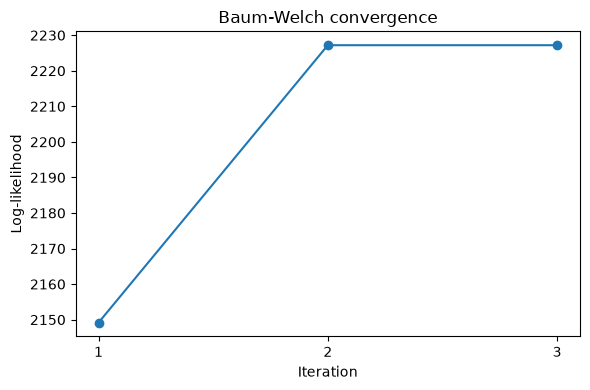

In [19]:
WINDOW_SEC = 2
VAR_FLOOR = 1e-3
SMOOTHING = 1.0
FEATURE_COLS = SELECTED_COLS

train_feats = build_feature_table(CLEAN_DIR / "train", WINDOW_SEC)
test_feats = build_feature_table(CLEAN_DIR / "test", WINDOW_SEC)
train_z, test_z = normalize(train_feats, test_feats, FEATURE_COLS)
train_z.to_csv(FEATURE_DIR / "train_features.csv", index=False)
test_z.to_csv(FEATURE_DIR / "test_features.csv", index=False)

model = train_hmm(train_z, VAR_FLOOR, SMOOTHING, FEATURE_COLS)
print(f"Baum-Welch stopped after {len(model.ll_history)} iterations "
      f"(converged: {model.converged})")
print(pd.DataFrame(model.A, index=ACTIVITIES, columns=ACTIVITIES).round(3))

plt.figure(figsize=(6, 4))
plt.plot(range(1, len(model.ll_history) + 1), model.ll_history, marker="o")
plt.xticks(range(1, len(model.ll_history) + 1))
plt.xlabel("Iteration")
plt.ylabel("Log-likelihood")
plt.title("Baum-Welch convergence")
plt.tight_layout()
plt.savefig(FIG_DIR / "convergence.png", dpi=150)
plt.show()

**Outcome:** Baum-Welch converged after 3 iterations: the log-likelihood rises in the first step and then stays flat, so the stopping rule (change below 0.001) is met well before the 200-iteration limit. Fast convergence is expected here, because the activities are well separated and the emissions start from the labelled windows. The learned transition matrix has about 0.89 to 0.90 on the diagonal, so the model strongly prefers to stay in the current activity.

The final features are saved in `features/`. The log-likelihood is positive because the Gaussians are narrow (small variances in z-score units), which makes their density values larger than 1. This is not an error.

## 6. Evaluation on Unseen Data

The test set contains **16 recordings (112 windows, 28 per activity)** from a separate session on 25 October 2026. They were not used for training, tuning or normalization statistics. Each recording is decoded separately with Viterbi, and the metrics are counted per 2 s window.

Metrics (one-vs-rest for each activity):
- **Sensitivity** = share of true windows of an activity that were found.
- **Specificity** = share of the other activities' windows that were correctly not labelled as this activity.
- **Accuracy** = share of all windows classified correctly. The *Overall* row gives the multi-class accuracy and the average sensitivity and specificity.

### 6.1. Predictions, metrics table and confusion matrix

State (Activity)  Number of Samples  Sensitivity  Specificity  Accuracy
        standing                 28        1.000        1.000     1.000
         walking                 28        1.000        0.988     0.991
         jumping                 28        0.964        1.000     0.991
           still                 28        1.000        1.000     1.000
         Overall                112        0.991        0.997     0.991


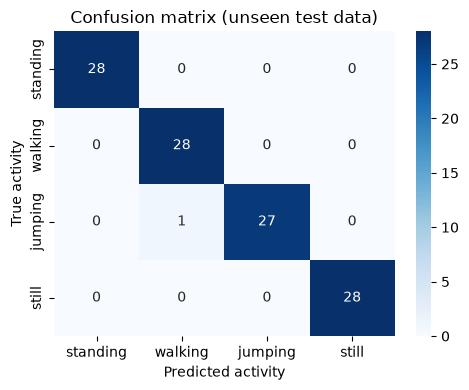

In [20]:
test_seqs, test_labels = to_sequences(test_z)
true = np.concatenate(test_labels)
pred = np.concatenate([model.viterbi(s) for s in test_seqs])


def confusion_matrix(true, pred, n_states):
    """Rows are the true activity, columns the predicted activity."""
    cm = np.zeros((n_states, n_states), dtype=int)
    np.add.at(cm, (true, pred), 1)
    return cm


def metrics_table(cm):
    """Sensitivity, specificity and accuracy for each activity (one-vs-rest)."""
    total = cm.sum()
    rows = []
    for k, name in enumerate(ACTIVITIES):
        tp = cm[k, k]
        fn = cm[k].sum() - tp
        fp = cm[:, k].sum() - tp
        tn = total - tp - fn - fp
        rows.append({"State (Activity)": name, "Number of Samples": int(cm[k].sum()),
                     "Sensitivity": tp / (tp + fn), "Specificity": tn / (tn + fp),
                     "Accuracy": (tp + tn) / total})
    table = pd.DataFrame(rows)
    overall = {"State (Activity)": "Overall", "Number of Samples": int(total),
               "Sensitivity": table["Sensitivity"].mean(),
               "Specificity": table["Specificity"].mean(),
               "Accuracy": np.trace(cm) / total}
    return pd.concat([table, pd.DataFrame([overall])], ignore_index=True)


cm = confusion_matrix(true, pred, len(ACTIVITIES))
results = metrics_table(cm)
print(results.round(3).to_string(index=False))
results.round(3).to_csv("results_table.csv", index=False)

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=ACTIVITIES,
            yticklabels=ACTIVITIES, ax=ax)
ax.set_xlabel("Predicted activity")
ax.set_ylabel("True activity")
ax.set_title("Confusion matrix (unseen test data)")
fig.tight_layout()
fig.savefig(FIG_DIR / "confusion_matrix.png", dpi=150)
plt.show()

**Outcome:** The model classified **111 of 112 unseen windows correctly (overall accuracy 0.991)**, with average sensitivity 0.991 and average specificity 0.997. Standing and still were classified perfectly. There is a single error: one *jumping* window predicted as *walking*. This lowers the jumping sensitivity to 0.964 and the walking specificity to 0.988. The test accuracy is very close to the cross-validation accuracy (0.997), so the model generalizes well to a new session. Section 6.2 explains the single error.

### 6.2. Error analysis
The next cell lists the misclassified windows, shows which features pushed the decision, and plots the signal around the wrong window.

     recording  window activity predicted
27  jumping_18       6  jumping   walking
               jumping  walking  favours
acc_log_std        1.2    -32.7  jumping
acc_log_sma      -60.8      1.5  walking
acc_corr          -1.1     -0.4  walking
acc_dom_freq      -3.0     -6.4  jumping
acc_entropy       -0.2     -0.7  jumping
gyro_log_std       0.8     -4.4  jumping
gyro_log_sma       0.3      2.0  walking
gyro_corr         -1.0     -4.0  jumping
gyro_dom_freq     -0.6      0.3  walking
gyro_entropy      -2.6     -0.7  walking
Total: -66.9 (jumping) vs -45.5 (walking)


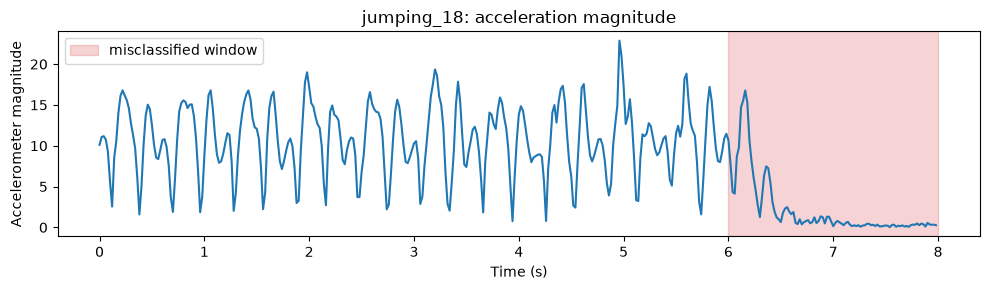

In [21]:
mask = true != pred
errors = test_z.loc[mask, ["recording", "window", "activity"]].assign(
    predicted=[ACTIVITIES[p] for p in pred[mask]])
print(errors)

if mask.any():
    # Log-density of the first wrong window under the true and the predicted state, per feature
    wrong = np.where(mask)[0][0]
    x = test_z.loc[mask, FEATURE_COLS].to_numpy()[0]
    true_k, pred_k = true[wrong], pred[wrong]

    def feature_loglik(k):
        """Log-density of the wrong window under state k, one value per feature."""
        return -0.5 * (np.log(2 * np.pi * model.vars[k]) + (x - model.means[k]) ** 2 / model.vars[k])

    contrib = pd.DataFrame({ACTIVITIES[true_k]: feature_loglik(true_k),
                            ACTIVITIES[pred_k]: feature_loglik(pred_k)}, index=FEATURE_COLS)
    contrib["favours"] = np.where(contrib[ACTIVITIES[true_k]] > contrib[ACTIVITIES[pred_k]],
                                  ACTIVITIES[true_k], ACTIVITIES[pred_k])
    print(contrib.round(1))
    print(f"Total: {contrib[ACTIVITIES[true_k]].sum():.1f} ({ACTIVITIES[true_k]}) "
          f"vs {contrib[ACTIVITIES[pred_k]].sum():.1f} ({ACTIVITIES[pred_k]})")

    # Where is the wrong window inside its recording?
    row = test_z.loc[mask, ["recording", "window"]].iloc[0]
    signal = pd.read_csv(CLEAN_DIR / "test" / f"{row['recording']}.csv")
    magnitude = np.linalg.norm(signal[SENSORS["acc"]].to_numpy(), axis=1)
    start = row["window"] * (1 - OVERLAP) * WINDOW_SEC

    fig, ax = plt.subplots(figsize=(10, 3))
    ax.plot(signal["timestamp"], magnitude)
    ax.axvspan(start, start + WINDOW_SEC, color="tab:red", alpha=0.2, label="misclassified window")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Accelerometer magnitude")
    ax.set_title(f"{row['recording']}: acceleration magnitude")
    ax.legend()
    fig.tight_layout()
    fig.savefig(FIG_DIR / "error_window.png", dpi=150)
    plt.show()

**Outcome:** The single error is the last window (6 to 8 s) of `jumping_18`: a jumping window predicted as walking. The signal plot shows that the jumping stops at about 6.3 s, so most of this window is quiet and it is really a transition window.

The per-feature table shows why. The variability features still match jumping (`acc_log_std` favours jumping by about 34 log-units), but the average movement level matches walking (`acc_log_sma` favours walking by about 62 log-units). Because the jumping Gaussian for `acc_log_sma` is very narrow, this single feature decides the prediction.

The error therefore comes mainly from a label that is only partly true at the end of the recording, and not from a failure on clear jumping windows. It is kept in the results: the reported accuracy is 99.1% (111 of 112), and without this boundary window it would be 111 of 111.

### 6.3. Transition and emission probabilities

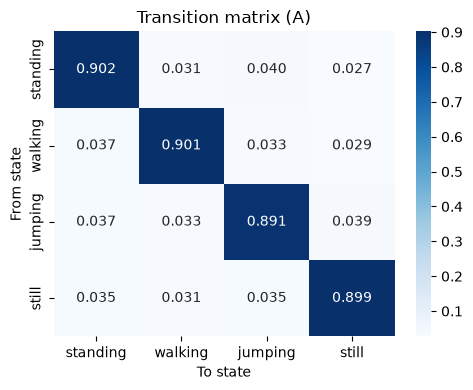

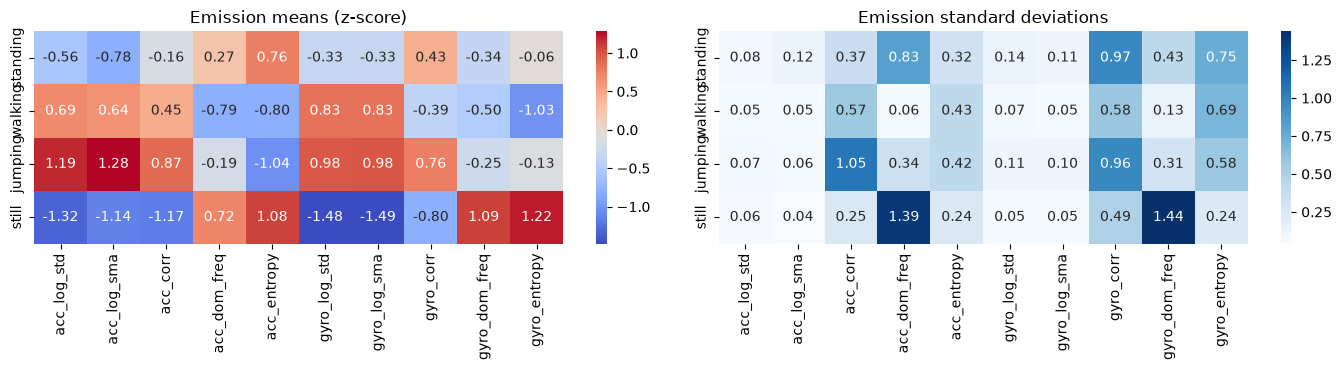

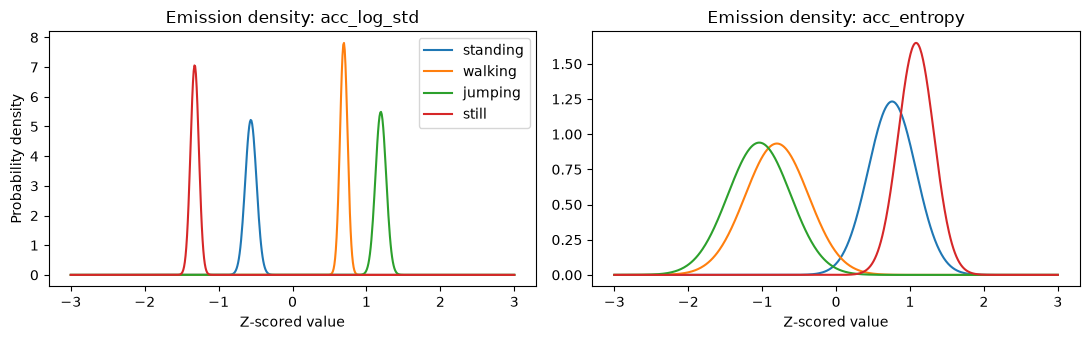

In [22]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(model.A, annot=True, fmt=".3f", cmap="Blues", xticklabels=ACTIVITIES,
            yticklabels=ACTIVITIES, ax=ax)
ax.set_xlabel("To state")
ax.set_ylabel("From state")
ax.set_title("Transition matrix (A)")
fig.tight_layout()
fig.savefig(FIG_DIR / "transition_matrix.png", dpi=150)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, values, title, cmap in [(axes[0], model.means, "Emission means (z-score)", "coolwarm"),
                                (axes[1], np.sqrt(model.vars), "Emission standard deviations", "Blues")]:
    sns.heatmap(pd.DataFrame(values, index=ACTIVITIES, columns=FEATURE_COLS),
                annot=True, fmt=".2f", cmap=cmap, ax=ax)
    ax.set_title(title)
fig.tight_layout()
fig.savefig(FIG_DIR / "emission_parameters.png", dpi=150)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, feature in zip(axes, ["acc_log_std", "acc_entropy"]):
    j = FEATURE_COLS.index(feature)
    x = np.linspace(-3, 3, 600)
    for k, name in enumerate(ACTIVITIES):
        mu, var = model.means[k, j], model.vars[k, j]
        ax.plot(x, np.exp(-0.5 * (x - mu) ** 2 / var) / np.sqrt(2 * np.pi * var), label=name)
    ax.set_title(f"Emission density: {feature}")
    ax.set_xlabel("Z-scored value")
axes[0].set_ylabel("Probability density")
axes[0].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "emission_densities.png", dpi=150)
plt.show()

**Transition matrix:** It is strongly diagonal (about 0.89 to 0.90): once in an activity, the model stays there with about 90% probability at the next window, which matches the fact that people keep an activity for several seconds. The off-diagonal values (0.03 to 0.04) are almost equal because the training sessions were built by chaining recordings in random order. They show that a switch is possible, but not which switches are more common in daily life.

**Emission probabilities:** Because the features are continuous, each state's emission is a Gaussian. The means follow the movement intensity on `log_std` and `log_sma` (still, standing, walking, jumping), and the densities of `acc_log_std` are four narrow peaks with almost no overlap. On `acc_entropy` two pairs overlap (standing with still, and walking with jumping), so entropy separates noise-like from rhythmic movement but not the activities inside each pair. The dominant frequency is very consistent for walking (standard deviation 0.06 in z-score units, a steady cadence) and very variable for still and standing, where the spectral peak is driven by noise.

### 6.4. Decoded sequence with transitions
The test recordings are joined into one session in the order standing, walking, jumping, still, repeated four times (16 recordings, 112 windows), and decoded as one sequence. The switches happen at recording boundaries, because the recordings are separate files.

Joined session accuracy: 0.991


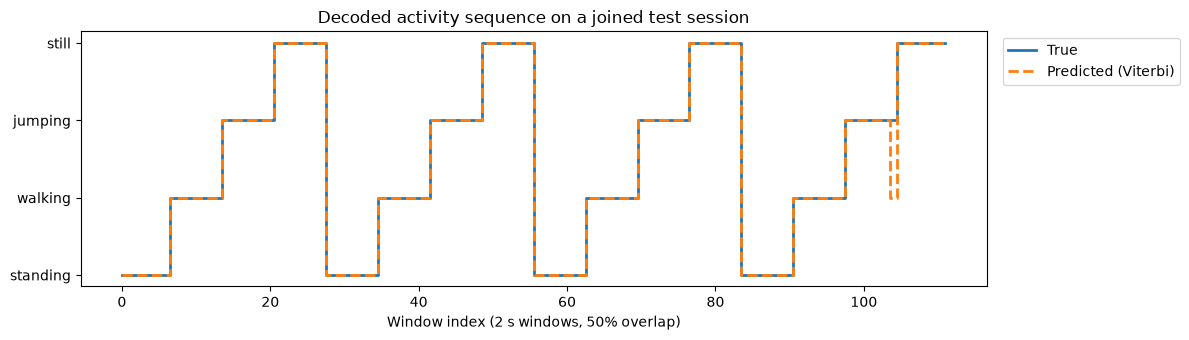

In [23]:
names = list(test_z["recording"].unique())
session_order = sorted(names, key=lambda n: (int(n.split("_")[1]), STATE_INDEX[n.split("_")[0]]))
by_name = dict(zip(names, zip(test_seqs, test_labels)))

session_X = np.vstack([by_name[n][0] for n in session_order])
session_true = np.concatenate([by_name[n][1] for n in session_order])
session_pred = model.viterbi(session_X)
print(f"Joined session accuracy: {(session_pred == session_true).mean():.3f}")

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.step(range(len(session_true)), session_true, where="mid", label="True", linewidth=2)
ax.step(range(len(session_pred)), session_pred, where="mid", label="Predicted (Viterbi)",
        linestyle="--", linewidth=2)
ax.set_yticks(range(len(ACTIVITIES)))
ax.set_yticklabels(ACTIVITIES)
ax.set_xlabel("Window index (2 s windows, 50% overlap)")
ax.set_title("Decoded activity sequence on a joined test session")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
fig.savefig(FIG_DIR / "decoded_sequence.png", dpi=150)
plt.show()

**Outcome:** The decoded sequence follows the true sequence closely: the activity switches are found at the right places, and the only deviation is the single misclassified window already seen in Section 6.1.

## 7. Analysis and Reflection

**Easiest and hardest activities:** *Still* and *standing* were the easiest to identify (perfect results). Their signal intensity is far below walking and jumping, and the log scale keeps the small difference between them visible. *Walking* and *jumping* were the hardest pair: both are periodic, their spectral entropy is similar, and their gyroscope intensities are close. The only test error was the last window of a jumping recording, where the jumping had already stopped (Section 6.2), so it is a boundary window rather than a clear jumping window.

**Transition probabilities:** The strong diagonal (about 0.9) reflects realistic persistence: people stay in an activity for a while before switching. The nearly uniform off-diagonal values come from the random order of the training sessions, so they do not describe real behavior patterns. Recording longer natural sessions with labelled switches would give more realistic transition probabilities.

**Sensor noise and sampling rate:** The phone recorded at about 49.8 Hz instead of exactly 50 Hz, so the signals were interpolated to an exact 50 Hz grid. Walking and jumping happen at low frequencies, far below the 25 Hz Nyquist limit, so 50 Hz is sufficient. Noise mainly affected the frequency features: for still and standing there is no real rhythm, so the dominant frequency has a very wide spread. The log scale and the tuned variance floor (0.001) prevented the model from becoming overconfident.

**Possible improvements:**
- More data from several people, phones and phone positions, since all data comes from one person and one phone.
- A larger test set: with 112 windows, one window is about 0.9 points of accuracy.
- Longer, naturally recorded sessions with real activity switches.
- More features (for example kurtosis, number of peaks, jerk) and more activities (running, stairs, sitting).
- Richer emission models, such as full-covariance Gaussians or Gaussian mixtures, so the model can represent combinations such as high variability with a low average level.
- Window-level labelling, so that windows at the start or end of an activity are not forced into one label.

**Conclusion:** A Gaussian HMM trained with Baum-Welch and decoded with Viterbi recognized four activities on unseen recordings with **99.1% accuracy** (111 of 112 windows). The results are consistent with the cross-validation, so the model generalizes to a new session of the same person and phone.